## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

    At low noise (0.125, 0.25) the three groups are tight, clearly separated blobs, and by 0.5 they start to touch at the edges. At 1.0 they overlap heavily, and at 2.0 they merge into one cloud with no visible clusters.


3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

    At low noise the scree plot has a sharp elbow at k=3 (SSE drops to almost 0 and goes flat), so picking k=3 is easy. As noise increases the elbow gets softer: at 1.0 it’s ambiguous between 2 and 3, and at 2.0 the curve is smooth with no elbow, so you can’t definitively choose k.

4. Explain the intuition of the elbow, using this numerical simulation as an example.

    Adding a cluster always lowers SSE, but before the true k it separates real groups (a big drop: 128.9 to 4.9 going from k=2 to k=3 at noise 0.125). After the true k it only splits a real group into pieces and fits noise (a tiny drop: 4.9 to 4.3). The elbow is where that payoff switches from big to small; with heavy noise, the spread within groups is as large as the distance between them, so there’s no clear switch.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?

    No real cleaning is needed: all four variables are already numeric with no odd values, and I get 148 countries. Just note that spending is in millions of USD, the percent columns are fractions (0.037 = 3.7%), and total spending is extremely skewed because of the US.

2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

    The scree plot bends at k=4. The clusters are the US alone; six rich, high per-capita spenders (Israel, Saudi Arabia, Kuwait, Oman, Norway, Singapore); about 30 wealthy developed countries; and everyone else. The US is its own cluster because its total spending is so extreme, which squishes everyone else together on that axis. That means the clusters mostly sort countries by per-capita spending, i.e. wealth, which is why China and India land in the low group.

3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?

    The elbow is around k=2 to 3; with k=3 the clusters measure military burden: low (~99 countries, including most of Europe and China), medium (~39, including the US, India, and Russia), and high (10, mostly Middle East/North Africa plus Armenia, Azerbaijan, and Pakistan). Unlike part 2, the US is no longer an outlier, because its spending is ordinary relative to its economy. Overall these groupings reflect priorities rather than wealth, so they look very different from part 2’s.

4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 

    The elbow is fuzzier, around k=3. The clusters are big spenders on every measure (US, Saudi Arabia, Israel, Kuwait, Oman, Singapore), high-burden but lower-income countries, and everyone else. The result mostly follows part 3, because the percent variables have more spread after normalization than total spending, which the US outlier dominates.

5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

    Somewhat. It showed that military spending has two separate dimensions, how much money a country spends versus how much of its economy it devotes, and it consistently flagged the Gulf states and Israel as high on everything. However, the US outlier, the unclear elbows, and the fact that countries form a continuum rather than distinct groups make it more of an exploratory summary than a definitive grouping.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

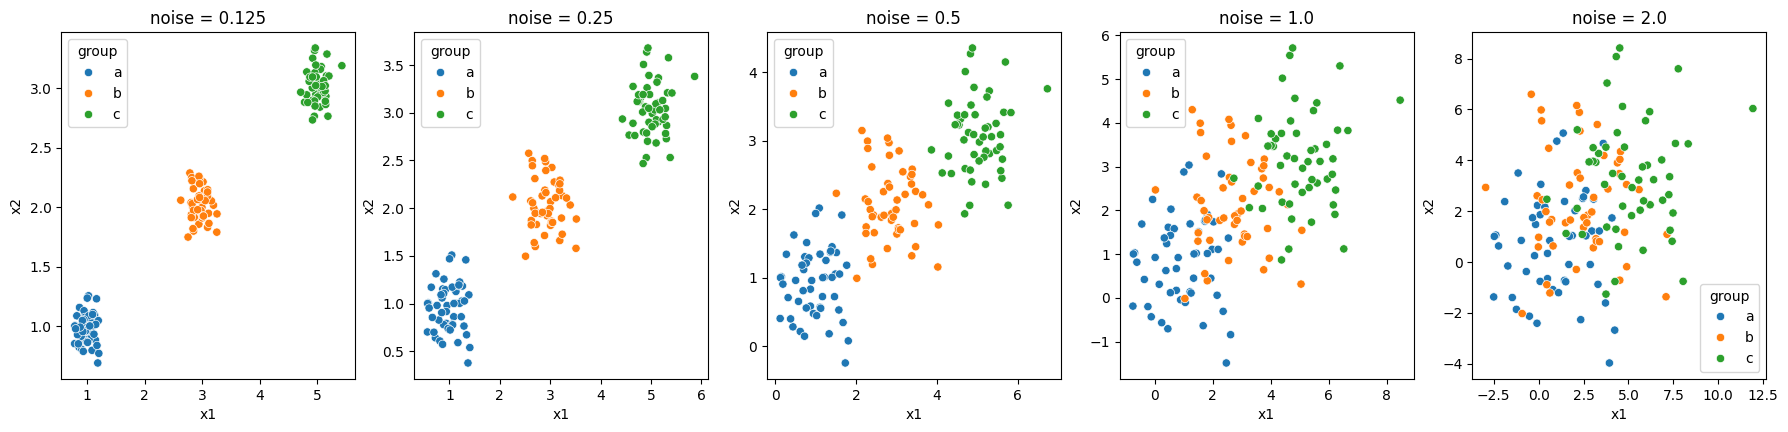

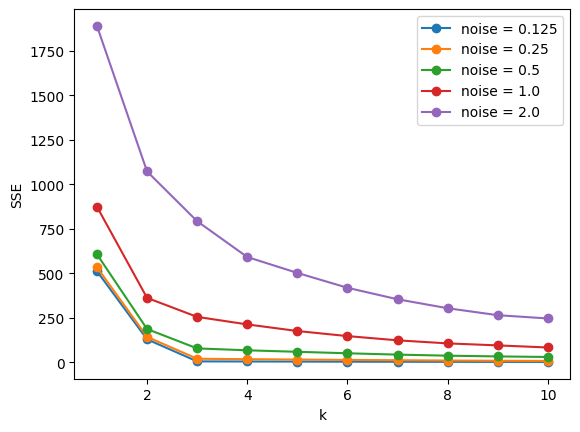

In [ ]:
# Your Phase 1 solution to the problem goes here.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans



def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(f'noise = {noise}')
plt.show()

def scree(X, max_k=10):
    sse = []
    for k in range(1, max_k + 1):
        model = KMeans(n_clusters=k, n_init=10, random_state=0)
        model.fit(X)
        sse.append(model.inertia_)
    return sse

k_values = list(range(1, 11))
for noise, df in datasets.items():
    plt.plot(k_values, scree(df[['x1', 'x2']]), marker='o', label=f'noise = {noise}')
plt.xlabel('k')
plt.ylabel('SSE')
plt.legend()
plt.show()

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


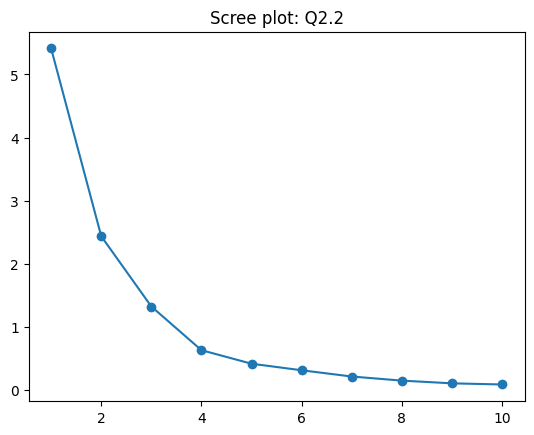

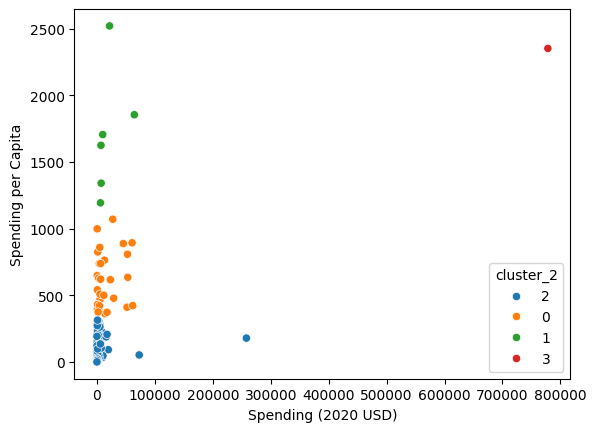

Spending (2020 USD)                                              \
                        count           mean           std            min   
cluster_2                                                                   
0                        30.0   17077.591354  20583.053357     405.790494   
1                         6.0   19443.362047  22861.507114    6095.708713   
2                       111.0    4859.185065  25405.739131       8.622460   
3                         1.0  778397.200000           NaN  778397.200000   

                                                                       \
                     25%            50%            75%            max   
cluster_2                                                               
0            2294.039665    5857.060906   26296.001003   61712.537169   
1            7023.251766    8624.225729   18857.070183   64558.400000   
2             130.010211     382.464677    2297.032353  257973.429834   
3          778397.200000  778397.200000  778397.200000  778397.200000   

          Spending per Capita                                        \
                        count         mean         std          min   
cluster_2                                                             
0                        30.0   607.478618  206.928757   362.467076   
1                         6.0  1706.721916  466.375705  1193.598730   
2                       111.0    80.061470   83.501824     0.580129   
3                         1.0  2351.631858         NaN  2351.631858   

                                                               
                   25%          50%          75%          max  
cluster_2                                                      
0           422.208252   579.004604   757.328513  1070.623322  
1          1412.083201  1665.447478  1817.219993  2520.398541  
2            14.880549    47.056944   125.387558   314.201312  
3          2351.631858  2351.631858  2351.631858  2351.631858

                       Country cluster_2
5540  United States of America         3
0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Ga

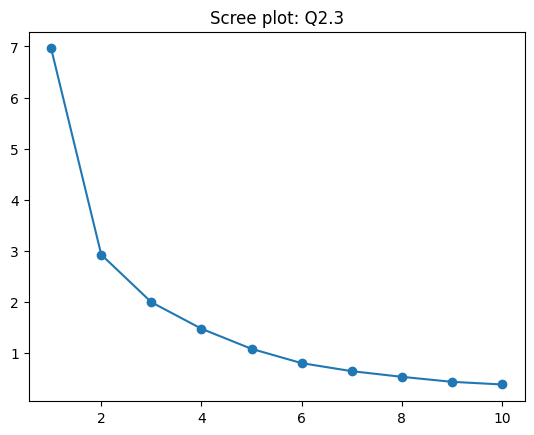

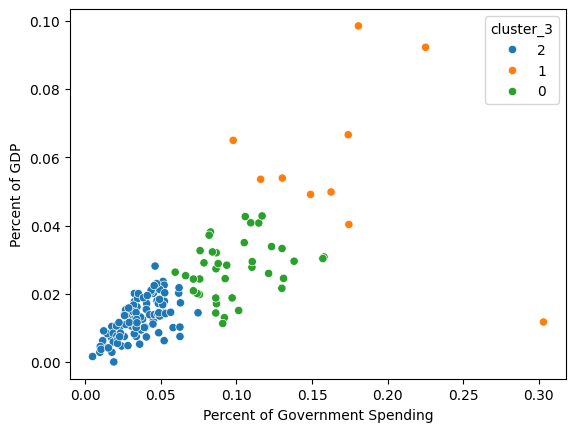

Percent of Government Spending                                \
                                   count      mean       std       min   
cluster_3                                                                
0                                   39.0  0.098683  0.024125  0.059520   
1                                   10.0  0.171289  0.058725  0.097882   
2                                   99.0  0.035777  0.014549  0.004896   

                                                  Percent of GDP            \
                25%       50%       75%       max          count      mean   
cluster_3                                                                    
0          0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1          0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2          0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                       
                std       min       25%       50%       75%       max  
cluster_3                                                              
0          0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1          0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2          0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

                       Country cluster_3
5540  United States of America         0
0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia',

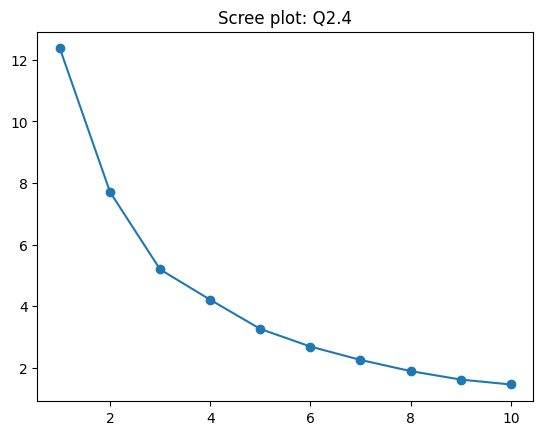

Spending (2020 USD)                                             \
                        count           mean            std          min   
cluster_4                                                                  
0                       111.0    7086.472777   26479.379918     8.622460   
1                        31.0    8786.086602   17901.909108   162.373364   
2                         6.0  147964.582042  309635.189564  6095.708713   

                                                                   \
                   25%           50%           75%            max   
cluster_4                                                           
0           130.010211    567.650747   3910.107493  257973.429834   
1           467.787851   1404.787234   7739.166193   72937.064048   
2          7700.424616  15897.570598  53872.942442  778397.200000   

          Spending per Capita               ...  \
                        count         mean  ...   
cluster_4                                   ...   
0                       111.0   196.926833  ...   
1                        31.0   212.689100  ...   
2                         6.0  1875.150751  ...   

          Percent of Government Spending           Percent of GDP            \
                                     75%       max          count      mean   
cluster_4                                                                     
0                               0.050505  0.092044          111.0  0.013419   
1                               0.134663  0.303027           31.0  0.033492   
2                               0.164503  0.225050            6.0  0.062634   

                                                                       
                std       min       25%       50%       75%       max  
cluster_4                                                              
0          0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1          0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
2          0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  

[3 rows x 32 columns]

                       Country cluster_4
5540  United States of America         2
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua',

In [ ]:
military = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = military[military['Year'] == 2020].dropna()
print(df.shape)
print(df.dtypes)

def maxmin(x):
    return (x - x.min()) / (x.max() - x.min())

vars_2 = ['Spending (2020 USD)', 'Spending per Capita']
X_2 = df[vars_2].apply(maxmin)

plt.plot(k_values, scree(X_2), marker='o')
plt.title('Scree plot: Q2.2')
plt.show()

df['cluster_2'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_2).labels_.astype(str)
sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_2')
plt.show()

display(df.groupby('cluster_2')[vars_2].describe())
print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_2']])
for c in sorted(df['cluster_2'].unique()):
    print(c, df.loc[df['cluster_2'] == c, 'Country'].tolist())

vars_3 = ['Percent of Government Spending', 'Percent of GDP']
X_3 = df[vars_3].apply(maxmin)

plt.plot(k_values, scree(X_3), marker='o')
plt.title('Scree plot: Q2.3')
plt.show()

df['cluster_3'] = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_3).labels_.astype(str)
sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_3')
plt.show()

display(df.groupby('cluster_3')[vars_3].describe())
print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_3']])
for c in sorted(df['cluster_3'].unique()):
    print(c, df.loc[df['cluster_3'] == c, 'Country'].tolist())

vars_4 = vars_2 + vars_3
X_4 = df[vars_4].apply(maxmin)

plt.plot(k_values, scree(X_4), marker='o')
plt.title('Scree plot: Q2.4')
plt.show()

df['cluster_4'] = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_4).labels_.astype(str)

display(df.groupby('cluster_4')[vars_4].describe())
print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_4']])
for c in sorted(df['cluster_4'].unique()):
    print(c, df.loc[df['cluster_4'] == c, 'Country'].tolist())

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [37]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]